
# Multi-Class Segmentation with Original Oxford-IIIT Pet Mask

The original segmentation mask contains **3 classes**:

- `1 = Pet`
- `2 = Pet boundary`
- `3 = Background`

For TensorFlow training, we change these to:

- `0 = Pet`
- `1 = Boundary`
- `2 = Background`

The model predicts one of these 3 classes for every pixel.


In [1]:
# !jupyter lab 2> >(grep -v "gpu_timer.cc" >&2)

In [2]:

!pip -q install tensorflow-datasets

import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt

print("TensorFlow:", tf.__version__)


2026-08-21 03:30:17.879760: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-08-21 03:30:17.905625: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8473] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-08-21 03:30:17.913363: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1471] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-08-21 03:30:17.934039: I tensorflow/core/platform/cpu_feature_guard.cc:211] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE3 SSE4.1 SSE4.2 AVX, in other operations, rebuild TensorFlow with the appropriate compiler flags.


AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

TensorFlow: 2.17.0


## 1. Load dataset

In [3]:

dataset, info = tfds.load(
    "oxford_iiit_pet:4.*.*",
    split="train",
    with_info=True
)

print("Examples:", info.splits["train"].num_examples)


Examples: 3680


2026-08-21 03:30:21.808609: I tensorflow/core/common_runtime/gpu/gpu_device.cc:2021] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 2956 MB memory:  -> device: 0, name: NVIDIA A100-SXM4-40GB MIG 1g.5gb, pci bus id: 0000:47:00.0, compute capability: 8.0


## 2. Preprocess image and original mask

In [4]:

IMG_SIZE = 128
BATCH_SIZE = 16
NUM_CLASSES = 3

def preprocess(data):
    image = data["image"]
    mask = data["segmentation_mask"]

    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))

    # Always use nearest-neighbour for class masks
    mask = tf.image.resize(
        mask,
        (IMG_SIZE, IMG_SIZE),
        method="nearest"
    )

    image = tf.cast(image, tf.float32) / 255.0

    # Original labels: 1, 2, 3
    # Training labels: 0, 1, 2
    mask = tf.cast(mask, tf.int32) - 1

    return image, mask


dataset = dataset.map(preprocess)

# Small dataset for testing
dataset = dataset.take(1000)

train_ds = dataset.take(800)
test_ds = dataset.skip(800)

train_ds = train_ds.shuffle(800).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


## 3. Show image and 3-class mask

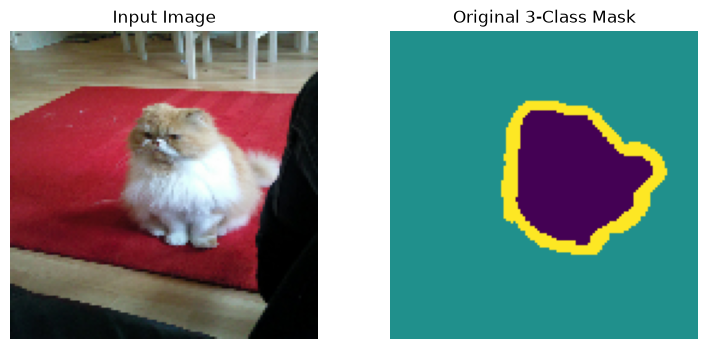

0 = Pet, 1 = Boundary, 2 = Background


2026-08-21 03:30:22.507777: I tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [5]:

for images, masks in train_ds.take(1):

    plt.figure(figsize=(9, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(images[0])
    plt.title("Input Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(
        masks[0, :, :, 0],
        cmap="viridis",
        vmin=0,
        vmax=2
    )
    plt.title("Original 3-Class Mask")
    plt.axis("off")

    plt.show()

print("0 = Pet, 1 = Boundary, 2 = Background")


## 4. Autoencoder model

In [6]:

model = tf.keras.Sequential([

    tf.keras.layers.Input(
        shape=(IMG_SIZE, IMG_SIZE, 3)
    ),

    # Encoder
    tf.keras.layers.Conv2D(
        16, 3,
        activation="relu",
        padding="same"
    ),
    tf.keras.layers.MaxPooling2D(2),

    tf.keras.layers.Conv2D(
        32, 3,
        activation="relu",
        padding="same"
    ),
    tf.keras.layers.MaxPooling2D(2),

    # Bottleneck
    tf.keras.layers.Conv2D(
        64, 3,
        activation="relu",
        padding="same"
    ),

    # Decoder
    tf.keras.layers.UpSampling2D(2),
    tf.keras.layers.Conv2D(
        32, 3,
        activation="relu",
        padding="same"
    ),

    tf.keras.layers.UpSampling2D(2),
    tf.keras.layers.Conv2D(
        16, 3,
        activation="relu",
        padding="same"
    ),

    # 3 output classes
    tf.keras.layers.Conv2D(
        3, 1,
        activation="softmax"
    )
])

model.summary()


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 128, 128, 16)      448       
                                                                 
 max_pooling2d (MaxPooling2  (None, 64, 64, 16)        0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 64, 64, 32)        4640      
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 32, 32, 32)        0         
 g2D)                                                            
                                                                 
 conv2d_2 (Conv2D)           (None, 32, 32, 64)        18496     
                                                                 
 up_sampling2d (UpSampling2  (None, 64, 64, 64)        0

## 5. Compile model

In [7]:

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


## 6. Train

In [8]:

history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=50
)


Epoch 1/50


2026-08-21 03:30:23.811559: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:531] Loaded cuDNN version 90600
W0000 00:00:1787283023.918867  199021 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1787283023.935039  199021 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1787283023.973037  199021 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1787283023.974349  199021 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1787283023.974880  199021 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1787283023.990947  199021 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1787283024.000525  199021 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1787283024.002337  199021 gpu_

 1/50 [..............................] - ETA: 3:02 - loss: 1.1335 - accuracy: 0.3339

'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
W0000 00:00:1787283026.539891  199025 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1787283026.540480  199025 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1787283026.541318  199025 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1787283026.541972  199025 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1787283026.542336  199025 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1787283026.543114  199025 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1787283026.544796  199025 gpu_timer.cc:114] Skipping

 2/50 [>.............................] - ETA: 31s - loss: 1.1186 - accuracy: 0.3314 

W0000 00:00:1787283027.122023  199021 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1787283027.122562  199021 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1787283027.123131  199021 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1787283027.123880  199021 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1787283027.124386  199021 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1787283027.124933  199021 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1787283027.125615  199021 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1787283027.127241  199021 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1787283027.128089  199021 gp

... (3 outputs left out)

W0000 00:00:1787283028.961784  199019 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1787283028.962123  199019 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1787283028.962563  199019 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1787283028.962923  199019 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1787283028.963135  199019 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1787283028.963554  199019 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1787283028.964423  199019 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1787283028.964857  199019 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1787283028.965499  199019 gp

Epoch 2/50
50/50 [==============================] - 2s 31ms/step - loss: 0.8419 - accuracy: 0.5981 - val_loss: 0.7723 - val_accuracy: 0.6522


W0000 00:00:1787283030.763709  199021 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1787283030.764080  199021 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1787283030.764531  199021 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1787283030.764903  199021 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1787283030.765121  199021 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1787283030.765548  199021 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1787283030.766424  199021 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1787283030.766859  199021 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1787283030.767487  199021 gp

Epoch 3/50
50/50 [==============================] - 2s 29ms/step - loss: 0.7798 - accuracy: 0.6445 - val_loss: 0.7543 - val_accuracy: 0.6614
Epoch 4/50
50/50 [==============================] - 2s 28ms/step - loss: 0.7743 - accuracy: 0.6480 - val_loss: 0.7416 - val_accuracy: 0.6700
Epoch 5/50
50/50 [==============================] - 2s 28ms/step - loss: 0.7305 - accuracy: 0.6795 - val_loss: 0.6903 - val_accuracy: 0.7034
Epoch 6/50
50/50 [==============================] - 2s 28ms/step - loss: 0.7203 - accuracy: 0.6811 - val_loss: 0.6817 - val_accuracy: 0.7029
Epoch 7/50
50/50 [==============================] - 2s 28ms/step - loss: 0.6857 - accuracy: 0.7021 - val_loss: 0.6537 - val_accuracy: 0.7226
Epoch 8/50
50/50 [==============================] - 2s 28ms/step - loss: 0.6781 - accuracy: 0.7060 - val_loss: 0.6446 - val_accuracy: 0.7214
Epoch 9/50
50/50 [==============================] - 2s 28ms/step - loss: 0.6388 - accuracy: 0.7295 - val_loss: 0.6128 - val_accuracy: 0.7433
Epoch 10/50
5

## 7. Plot loss

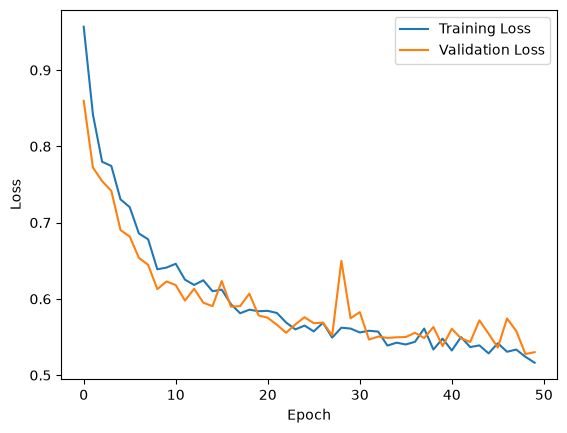

In [9]:

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()


## 8. Predict original 3-class masks

1/1 [==============================] - 0s 219ms/step


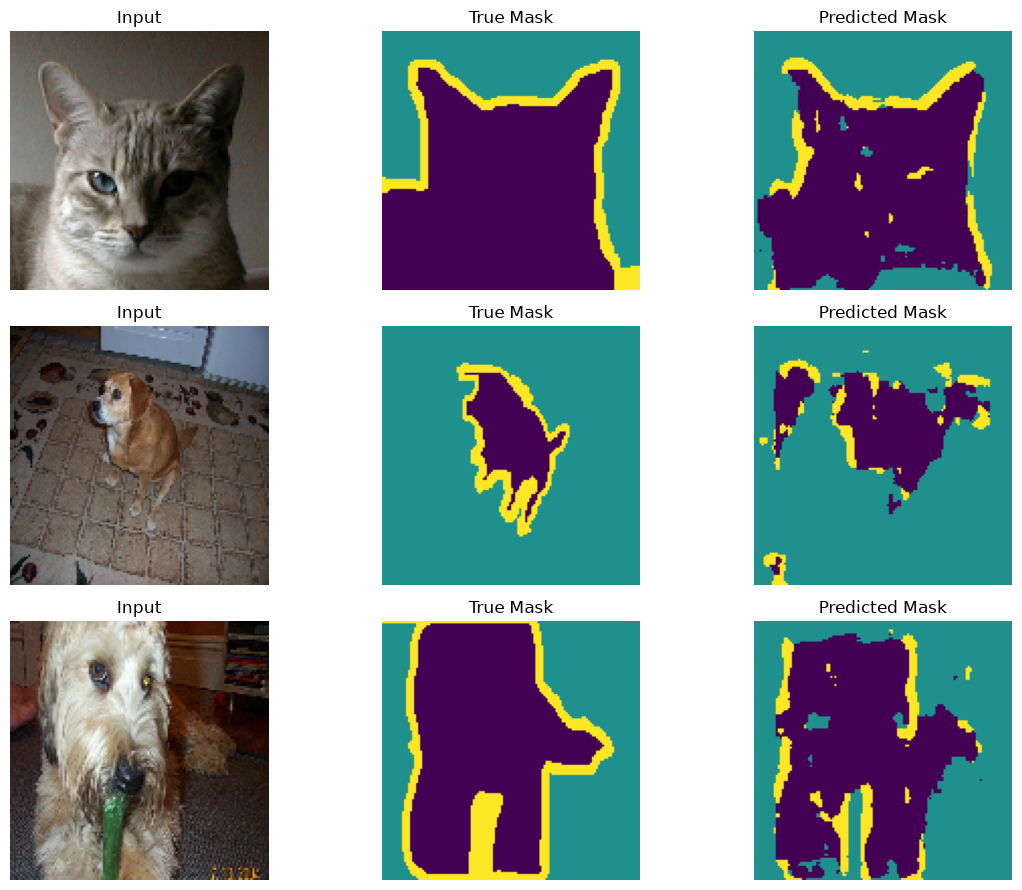

0 = Pet, 1 = Boundary, 2 = Background


2026-08-21 03:31:50.245283: I tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [10]:

for images, masks in test_ds.take(1):

    predictions = model.predict(images)

    # Softmax output -> class number 0, 1 or 2
    predicted_masks = tf.argmax(
        predictions,
        axis=-1
    )

    plt.figure(figsize=(12, 9))

    for i in range(3):

        plt.subplot(3, 3, i * 3 + 1)
        plt.imshow(images[i])
        plt.title("Input")
        plt.axis("off")

        plt.subplot(3, 3, i * 3 + 2)
        plt.imshow(
            masks[i, :, :, 0],
            cmap="viridis",
            vmin=0,
            vmax=2
        )
        plt.title("True Mask")
        plt.axis("off")

        plt.subplot(3, 3, i * 3 + 3)
        plt.imshow(
            predicted_masks[i],
            cmap="viridis",
            vmin=0,
            vmax=2
        )
        plt.title("Predicted Mask")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

print("0 = Pet, 1 = Boundary, 2 = Background")


## 9. Evaluate model

In [11]:

test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Pixel Accuracy:", test_accuracy)


13/13 [==============================] - 0s 11ms/step - loss: 0.5302 - accuracy: 0.7835
Test Loss: 0.5301525592803955
Pixel Accuracy: 0.7834988236427307
